# 05 - Avaliação final no teste de 2015

Bloco 8 do plano da Parte 2. É o único sítio onde o teste de 2015 é usado. Os modelos chegam aqui **congelados**: a configuração de cada um, o limiar da classificação e o pipeline treinado em todo o treino foram gravados pelo `scripts/freeze_models.py` antes de o teste ser aberto, e o JSON de cada tarefa está no Git com a tag `modelos-congelados`.

**Regras deste notebook**

- Não treina nem escolhe nada: lê os pipelines congelados (confirmando o hash de cada ficheiro) e prevê o teste.
- As previsões ficam guardadas em `data/processed/test_predictions/`. Voltar a correr o notebook lê-as do ficheiro; se as escolhas congeladas mudarem, o notebook para com um erro.
- Se um resultado do teste for mau, o modelo **não se muda**: discute-se no relatório.

**Antes de correr:** congelar as duas tarefas, fazer commit dos dois JSON e a tag (ver `docs/05_avaliacao/avaliacao_final.md`).

| Requisito do enunciado | Onde |
|---|---|
| *"Preserve a final test set for final evaluation"* | Secção 1 (tag e hashes) e todo o notebook |
| *"The mean and the variation of the metric in the cross-validation procedures and the mean in the test dataset"* | Secções 3.2 e 4.2 |
| *"One comparison table for each task, including baselines"* | Secções 3.2 e 4.2 |
| Matriz de confusão, *precision*, *recall* e F1 (macro e micro), AUC, *accuracy* | Secções 4.2 e 4.4 |
| Incerteza no teste (bootstrap, T03) | Secções 3.2, 3.3, 4.2 e 4.3 |
| *"Selection bias, unequal follow-up, temporal change, fairness"* | Secções 2, 3.4, 3.5, 4.5, 4.6 e 5 |

In [1]:
# Setup: imports e caminhos do projeto
import sys
from pathlib import Path

# Importar o pacote do projeto.
try:
    import lending
except ModuleNotFoundError:
    for parent in [Path.cwd(), *Path.cwd().parents]:
        if (parent / "src" / "lending").is_dir():
            sys.path.insert(0, str(parent / "src"))
            break
    import lending

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from lending import config
from lending.cohorts import TARGET_CLASSES
from lending.experiment import RESULTS_DIR
from lending.final_evaluation import (TAG, FinalEvaluation, load_frozen, parse_mean_std,
                                      tag_status, test_cohort)
from lending.plot_style import apply_style
from lending.storage import PickleStore

apply_style()
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)

REQUIRE_TAG = True    # False só para ensaiar o notebook com dados falsos
N_BOOT = 1000         # reamostragens do bootstrap (T03, p. 41 e 62)
GROUPS = ["região", "home_ownership", "rendimento"]
TASKS = ["regression", "classification"]

## 1. Os modelos congelados

Para cada tarefa: o JSON congelado tem de ser igual ao que está na tag `modelos-congelados` (senão, alguma escolha mudou depois da tag). A tabela mostra o que vai ao teste: a melhor configuração de cada modelo na validação cruzada, as *baselines* e o modelo final.

In [2]:
frozen = {task: load_frozen(task) for task in TASKS}
status = {task: tag_status(task) for task in TASKS}
for task in TASKS:
    record = frozen[task]
    print(f"{task}: tag {status[task]} | congelado em {record['frozen_at']} (commit {record['git_commit']}) | "
          f"modelo final: {record['final_model']}")
    if record.get("uncommitted_code_changes"):
        print(f"  AVISO: havia código por gravar quando {task} foi congelada")
problems = {task: s for task, s in status.items() if s != "ok"}
if problems and REQUIRE_TAG:
    raise RuntimeError(f"Sem a tag {TAG} certa: {problems}. Ver docs/05_avaliacao/avaliacao_final.md")

rows = []
for task in TASKS:
    metric = "mae" if task == "regression" else "f1_macro"
    for e in frozen[task]["models"]:
        rows.append({"tarefa": task, "modelo": e["model"], "final": "sim" if e["model"] == frozen[task]["final_model"] else "",
                     "configuração": e["params"] or "—", "limiar": e["threshold"],
                     "métrica da escolha (CV)": e["cv"].get(metric, "—"), "n treino": e["n_train"],
                     "treino (s)": e["fit_seconds"], "ficheiro (MB)": e["size_mb"]})
pd.DataFrame(rows).set_index(["tarefa", "modelo"])

regression: tag ok | congelado em 2026-11-21T20:36:35 (commit 1b4a196) | modelo final: LightGBM
classification: tag ok | congelado em 2026-11-21T20:37:10 (commit 1b4a196) | modelo final: Regressão logística final


final  \
tarefa         modelo                            
regression     LightGBM                    sim   
               MLP                               
               Ridge                             
               Random Forest                     
               Árvore                            
               kNN                               
               Mediana por prazo                 
               Mediana                           
classification MLP                               
               Regressão logística               
               Random Forest                     
               LightGBM                          
               kNN                               
               Árvore                            
               Taxa do grau                      
               Classe maioritária                
               Regressão logística final   sim   

                                                                               configuração  \
tarefa         modelo                                                                         
regression     LightGBM                           {'learning_rate': 0.05, 'num_leaves': 63}   
               MLP                        {'hidden_layers': [256, 128, 64], 'learning_ra...   
               Ridge                                                        {'alpha': 10.0}   
               Random Forest                  {'max_features': 0.3, 'min_samples_leaf': 10}   
               Árvore                             {'max_depth': 12, 'min_samples_leaf': 50}   
               kNN                               {'n_neighbors': 31, 'weights': 'distance'}   
               Mediana por prazo                                                          —   
               Mediana                                                                    —   
classification MLP                        {'hidden_layers': [256, 128, 64], 'learning_ra...   
               Regressão logística                                               {'C': 0.1}   
               Random Forest                  {'max_features': 0.3, 'min_samples_leaf': 50}   
               LightGBM                            {'learning_rate': 0.1, 'num_leaves': 63}   
               kNN                              {'n_neighbors': 101, 'weights': 'distance'}   
               Árvore                              {'max_depth': 6, 'min_samples_leaf': 50}   
               Taxa do grau                                                               —   
               Classe maioritária                                                         —   
               Regressão logística final                                         {'C': 0.1}   

                                          limiar métrica da escolha (CV)  \
tarefa         modelo                                                      
regression     LightGBM                      NaN           2.144 ± 0.419   
               MLP                           NaN           2.165 ± 0.346   
               Ridge                         NaN           2.221 ± 0.332   
               Random Forest                 NaN           2.257 ± 0.292   
               Árvore                        NaN           2.445 ± 0.290   
               kNN                           NaN           2.490 ± 0.153   
               Mediana por prazo             NaN           3.144 ± 0.196   
               Mediana                       NaN           3.512 ± 0.162   
classification MLP                          0.56           0.573 ± 0.008   
               Regressão logística          0.56           0.570 ± 0.010   
               Random Forest                0.52           0.564 ± 0.021   
               LightGBM                     0.52           0.561 ± 0.008   
               kNN                          0.52           0.555 ± 0.011   
               Árvore                       0.62           0.541 ± 0.011   
               Taxa do grau                 0.21           0.513 ± 0

## 2. Coortes de teste

As coortes de 2015 saem do mesmo `CohortBuilder` do treino, com `partition="test"`, a partir do teste limpo na Parte 1 com as mesmas regras (`docs/02_preprocessamento/teste_final.md`). Todas as linhas removidas ficam registadas.

- **Regressão:** todos os empréstimos de 2015 com `int_rate` (36 e 60 meses, incluindo os ainda ativos: a taxa é conhecida no pedido).
- **Classificação:** só 36 meses e só com o desfecho conhecido. Os empréstimos de 2015 a 36 meses acabaram o prazo até ao fim de 2018, antes da extração (2019-03), por isso quase todos têm desfecho. Os *At risk* (ainda em atraso depois do fim do prazo) contam como *Default*, como decidido na Parte 1; a coluna `target_3` guarda as 3 classes do enunciado para a tabela 3 × 2.

In [3]:
raw_test = PickleStore.load(config.TEST_PKL, expected_type=pd.DataFrame)
test_reg, log_reg = test_cohort("regression", raw_test)
test_cls, log_cls = test_cohort("classification", raw_test)
print(f"Teste limpo: {len(raw_test):,} empréstimos | regressão: {len(test_reg):,} | classificação: {len(test_cls):,}")
pd.concat({"regressão": log_reg.to_frame(), "classificação": log_cls.to_frame()})

Teste limpo: 420,888 empréstimos | regressão: 420,888 | classificação: 282,996


step      kind  \
              n                                                   
regressão     1  Fora do período de test da regressão  partição   
              2                      Sem taxa de juro   remoção   
classificação 1                     Prazo de 60 meses   remoção   
              2               Fora do período de test  partição   
              3                 Desfecho desconhecido   remoção   

                                              rule  \
              n                                      
regressão     1  issue_d fora de 2015-01 a 2015-12   
              2                  int_rate em falta   
classificação 1                         term != 36   
              2  issue_d fora de 2015-01 a 2015-12   
              3  loan_status = Current ou em falta   

                                                            reason  \
              n                                                      
regressão     1               Só os empréstimos do período de test   
              2                     int_rate é o alvo da regressão   
classificação 1  Não terminam a tempo de o desfecho ser observa...   
              2               Só os empréstimos do período de test   
              3  O desfecho final ainda não é conhecido (enunci...   

                 rows_before  rows_removed  rows_after  
              n                                         
regressão     1       420888             0      420888  
              2       420888             0      420888  
classificação 1       420888        137820      283068  
              2       283068             0      283068  
              3       283068            72      282996

In [4]:
# Classes da classificação: as 3 do enunciado e as 2 usadas, no treino (2007-2011) e no teste (2015)
train_cls = PickleStore.load(config.CLS_TRAIN_PKL, expected_type=pd.DataFrame)
classes = pd.DataFrame({
    "treino": train_cls["loan_status"].map(TARGET_CLASSES).value_counts(),
    "teste": test_cls["target_3"].value_counts()}).reindex(["Good standing", "At risk", "Default"]).fillna(0).astype(int)
classes["teste (%)"] = (100 * classes["teste"] / classes["teste"].sum()).round(2)
classes["teste, binário"] = ["Good standing", "Default", "Default"]
classes

,treino,teste,teste (%),"teste, binário"
Good standing,27646,240792,85.09,Good standing
At risk,0,75,0.03,Default
Default,3876,42129,14.89,Default


## 3. Regressão: taxa de juro em T0

### 3.1 Previsões

Cada pipeline congelado (pré-processamento + modelo, treinado em todo o treino de 2013–2014) prevê o teste uma vez. O tempo de treino é o do congelamento; o de previsão é o deste notebook (ou o da primeira execução, se as previsões já estavam guardadas).

In [5]:
train_reg = PickleStore.load(config.REG_DEV_PKL, expected_type=pd.DataFrame)
reg = FinalEvaluation("regression", train_reg, test_reg, frozen=frozen["regression"])
reg.predict()
reg.timing

,treino (s),previsão do teste (s)
modelo,,
LightGBM,26.0,7.6
MLP,58.4,4.6
Ridge,8.6,3.7
Random Forest,68.3,7.7
Árvore,28.4,3.1
kNN,7.9,260.8
Mediana por prazo,0.1,0.0
Mediana,0.1,0.0


### 3.2 Tabela de comparação: validação cruzada e teste

Uma linha por modelo, pela ordem da validação cruzada (a escolha não muda com o teste). "CV" é a média ± desvio-padrão nos 6 folds trimestrais; "teste" é o valor em 2015, com o intervalo de confiança a 95% por bootstrap (1 000 reamostragens dos empréstimos de teste).

**Como ler:** um MAE de teste dentro da variação entre folds quer dizer que o modelo generaliza para um ano que nunca viu. Um MAE claramente acima é sinal de mudança temporal (secção 3.4), não de *overfitting* à validação: as escolhas foram feitas antes de ver 2015.

In [6]:
reg_table = reg.metrics_table(N_BOOT)
reg_table.to_csv(RESULTS_DIR / "regression_test.csv")
reg_table

,final,configuração,n treino,MAE (CV),MAE (teste),IC 95% MAE,RMSE (CV),RMSE (teste),IC 95% RMSE,R² (CV),R² (teste),IC 95% R²,treino (s)
modelo,,,,,,,,,,,,,
LightGBM,sim,"{""learning_rate"": 0.05, ""num_leaves"": 63}",370278,2.144 ± 0.419,2.690,[2.685; 2.696],2.697 ± 0.494,3.299,[3.293; 3.305],0.603 ± 0.157,0.416,[0.413; 0.420],26.0
MLP,,"{""hidden_layers"": [256, 128, 64], ""learning_ra...",370278,2.165 ± 0.346,2.718,[2.713; 2.723],2.723 ± 0.414,3.276,[3.270; 3.282],0.600 ± 0.141,0.424,[0.422; 0.427],58.4
Ridge,,"{""alpha"": 10.0}",370278,2.221 ± 0.332,2.653,[2.648; 2.659],2.776 ± 0.388,3.242,[3.236; 3.249],0.587 ± 0.133,0.436,[0.433; 0.439],8.6
Random Forest,,"{""max_features"": 0.3, ""min_samples_leaf"": 10}",370278,2.257 ± 0.292,2.665,[2.659; 2.671],2.821 ± 0.329,3.230,[3.224; 3.237],0.576 ± 0.121,0.440,[0.438; 0.443],68.3
Árvore,,"{""max_depth"": 12, ""min_samples_leaf"": 50}",370278,2.445 ± 0.290,2.800,[2.795; 2.807],3.078 ± 0.328,3.432,[3.425; 3.439],0.496 ± 0.131,0.368,[0.365; 0.372],28.4
kNN,,"{""n_neighbors"": 31, ""weights"": ""distance""}",50000,2.490 ± 0.153,2.837,[2.831; 2.843],3.176 ± 0.162,3.472,[3.465; 3.480],0.471 ± 0.075,0.353,[0.351; 0.356],7.9
Mediana por prazo,,—,370278,3.144 ± 0.196,3.425,[3.418; 3.433],3.929 ± 0.194,4.152,[4.145; 4.160],0.195 ± 0.056,0.075,[0.072; 0.078],0.1
Mediana,,—,370278,3.512 ± 0.162,3.726,[3.718; 3.733],4.404 ± 0.151,4.533,[4.525; 4.541],-0.011 ± 0.019,-0.102,[-0.104; -0.100],0.1


### 3.3 O modelo final contra os outros (bootstrap emparelhado)

A diferença de MAE entre o modelo final e cada um dos outros, nas mesmas reamostragens do teste. Negativo quer dizer que o modelo final erra menos. Se o intervalo contém o 0, os dois não se distinguem no teste.

In [7]:
reg_paired = reg.paired_table(n_boot=N_BOOT)
reg_paired.to_csv(RESULTS_DIR / "regression_test_paired.csv")
reg_paired

,MAE: diferença,IC 95% MAE,MAE: clara
outro modelo,,,
MLP,-0.0275,[-0.0302; -0.0249],sim
Ridge,0.0371,[0.0337; 0.0407],sim
Random Forest,0.0253,[0.0219; 0.0287],sim
Árvore,-0.1098,[-0.1141; -0.1052],sim
kNN,-0.1468,[-0.1527; -0.1410],sim
Mediana por prazo,-0.7349,[-0.7427; -0.7267],sim
Mediana,-1.0352,[-1.0444; -1.0260],sim


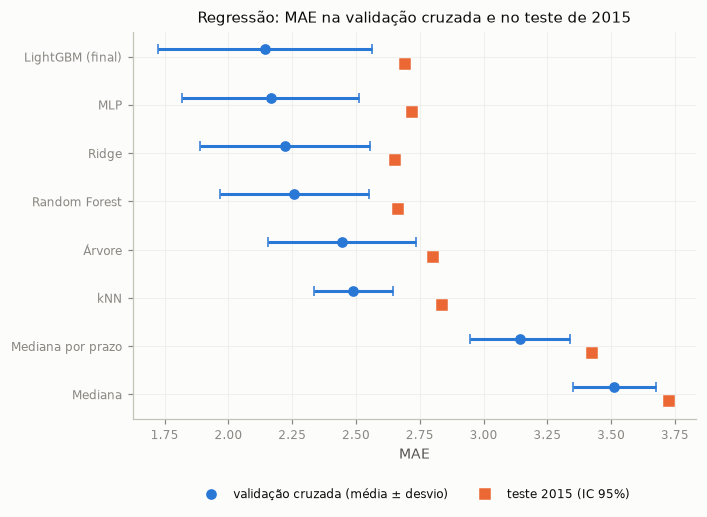

In [8]:
ax = reg.plot_cv_vs_test("mae")
ax.set_title("Regressão: MAE na validação cruzada e no teste de 2015")
ax.figure.tight_layout()
ax.figure.savefig(config.FIGURES_DIR / "final_reg_cv_teste.png")
plt.show()

### 3.4 Mudança temporal: o erro ao longo de 2015

O 04b mostrou o MAE de cada trimestre de validação em 2013–2014. Aqui continua-se a mesma linha em 2015, mês a mês, com o modelo final. Um viés sistemático (sempre acima ou abaixo de 0) quer dizer que o nível das taxas mudou face ao treino; um MAE a subir ao longo do ano quer dizer que o modelo envelhece e precisa de ser retreinado (plano de deployment).

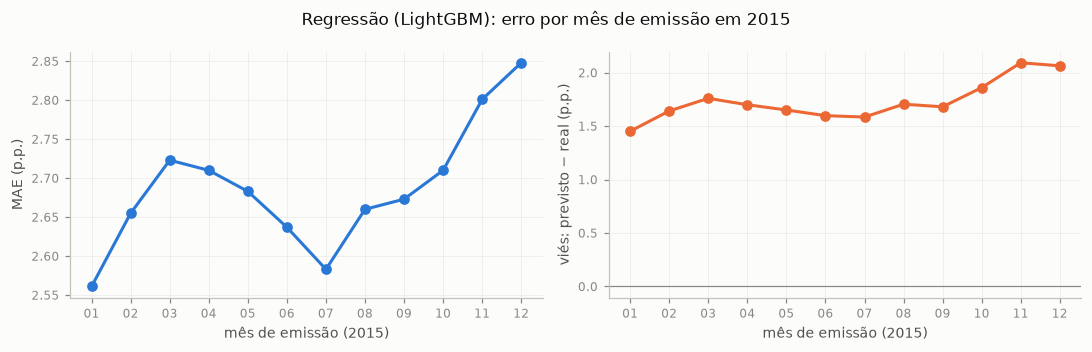

,n,taxa real média,taxa prevista média,MAE,viés
2015-01,35090.0,13.055,14.507,2.561,1.452
2015-02,23764.0,12.728,14.370,2.655,1.642
2015-03,25394.0,12.773,14.534,2.723,1.760
2015-04,35412.0,12.791,14.491,2.710,1.700
2015-05,31896.0,12.752,14.404,2.683,1.651
2015-06,28472.0,12.763,14.361,2.637,1.598
2015-07,45946.0,12.707,14.292,2.583,1.585
2015-08,35861.0,12.594,14.299,2.660,1.705
2015-09,28631.0,12.660,14.341,2.673,1.681
2015-10,48607.0,12.283,14.143,2.710,1.860


In [9]:
reg_months = reg.by_period()
axes = reg.plot_by_period()
axes[0].figure.suptitle(f"Regressão ({reg.final_model}): erro por mês de emissão em 2015")
axes[0].figure.tight_layout()
axes[0].figure.savefig(config.FIGURES_DIR / "final_reg_por_mes.png")
plt.show()
reg_months

### 3.5 Equidade: o erro por grupo

O enunciado pede para discutir a equidade. A geografia ficou fora dos modelos (possível *proxy* de grupos protegidos), por isso mede-se aqui se o erro é igual nas regiões dos EUA, nos tipos de habitação e nos quintis de rendimento (com os limites do treino). Um viés positivo num grupo quer dizer que o modelo lhe "cobra" mais do que a LendingClub cobrou. Grupos com menos de 1 000 empréstimos juntam-se em "outros".

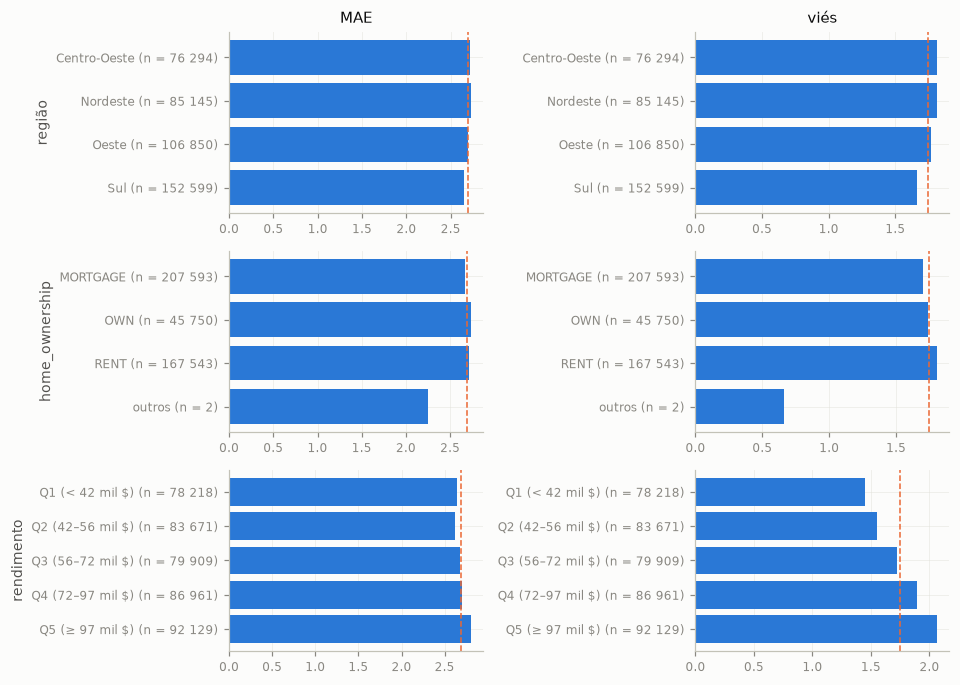

n  taxa real média  \
região         Centro-Oeste       76294.0           12.598   
               Nordeste           85145.0           12.479   
               Oeste             106850.0           12.542   
               Sul               152599.0           12.713   
               total             420888.0           12.601   
home_ownership MORTGAGE          207593.0           12.318   
               OWN                45750.0           12.657   
               RENT              167543.0           12.938   
               outros                 2.0           15.515   
               total             420888.0           12.601   
rendimento     Q1 (< 42 mil $)    78218.0           13.556   
               Q2 (42–56 mil $)   83671.0           13.032   
               Q3 (56–72 mil $)   79909.0           12.683   
               Q4 (72–97 mil $)   86961.0           12.254   
               Q5 (≥ 97 mil $)    92129.0           11.658   
               total             420888.0           12.601   

                                 taxa prevista média    MAE   viés  
região         Centro-Oeste                   14.412  2.714  1.814  
               Nordeste                       14.293  2.727  1.814  
               Oeste                          14.306  2.694  1.764  
               Sul                            14.379  2.655  1.666  
               total                          14.349  2.690  1.748  
home_ownership MORTGAGE                       14.019  2.665  1.702  
               OWN                            14.397  2.734  1.740  
               RENT                           14.744  2.709  1.807  
               outros                         16.179  2.248  0.664  
               total                          14.349  2.690  1.748  
rendimento     Q1 (< 42 mil $)                15.004  2.639  1.448  
               Q2 (42–56 mil $)               14.587  2.619  1.555  
               Q3 (56–72 mil $)               14.403  2.674  1.720  
               Q4 (72–97 mil $)               14.144  2.701  1.890  
               Q5 (≥ 97 mil $)                13.723  2.804  2.066  
               total                          14.349  2.690  1.748

In [10]:
reg_groups = pd.concat({by: reg.subgroup_table(by) for by in GROUPS})
reg_groups.to_csv(RESULTS_DIR / "regression_test_subgroups.csv")
fig = reg.plot_subgroups(GROUPS, ["MAE", "viés"])
fig.savefig(config.FIGURES_DIR / "final_reg_equidade.png")
plt.show()
reg_groups

## 4. Classificação: risco de *default* em T4

### 4.1 Previsões

Cada pipeline congelado (treinado em todos os empréstimos de 36 meses de 2007–2011) dá a P(Default) de cada empréstimo de teste. A classe prevista usa o limiar **congelado** de cada modelo, escolhido nas previsões fora do fold (máximo do F1 macro); nunca é afinado no teste.

In [11]:
cls = FinalEvaluation("classification", train_cls, test_cls, frozen=frozen["classification"])
cls.predict()
cls.timing

,treino (s),previsão do teste (s)
modelo,,
MLP,15.7,3.4
Regressão logística,1.4,3.1
Random Forest,3.5,3.6
LightGBM,2.4,2.8
kNN,1.2,129.6
Árvore,1.5,2.7
Taxa do grau,0.0,0.0
Classe maioritária,0.0,0.0
Regressão logística final,1.4,2.6


### 4.2 Tabela de comparação: validação cruzada e teste

As métricas pedidas pelo enunciado, com a média ± desvio-padrão nos 3 folds anuais e o valor no teste (com IC 95% por bootstrap). A segunda tabela tem todas as métricas no teste (*precision*, *recall* e F1 em macro e micro); na classificação binária, o F1 micro é igual à *accuracy*.

**Como ler:** o F1 macro e a AUC são as métricas principais (a *accuracy* é enganadora com ~15% de *Default*: a classe maioritária tem *accuracy* alta e não apanha nenhum). A taxa de *Default* do teste não é a do treino (secção 5), e o F1 depende dessa taxa; a AUC não, por isso é a melhor comparação direta entre a validação e o teste.

In [12]:
cls_table = cls.metrics_table(N_BOOT)
cls_table.to_csv(RESULTS_DIR / "classification_test.csv")
cls_table

,final,configuração,n treino,limiar,F1 macro (CV),F1 macro (teste),IC 95% F1 macro,AUC (CV),AUC (teste),IC 95% AUC,recall Default (CV),recall Default (teste),IC 95% recall Default,accuracy (CV),accuracy (teste),IC 95% accuracy,treino (s)
modelo,,,,,,,,,,,,,,,,,
MLP,,"{""hidden_layers"": [256, 128, 64], ""learning_ra...",31522,0.56,0.573 ± 0.008,0.560,[0.558; 0.562],0.666 ± 0.025,0.660,[0.658; 0.663],0.257 ± 0.005,0.464,[0.460; 0.469],0.819 ± 0.023,0.697,[0.696; 0.699],15.7
Regressão logística,,"{""C"": 0.1}",31522,0.56,0.570 ± 0.010,0.569,[0.567; 0.571],0.669 ± 0.021,0.660,[0.657; 0.663],0.259 ± 0.020,0.378,[0.373; 0.382],0.814 ± 0.028,0.737,[0.736; 0.739],1.4
Random Forest,,"{""max_features"": 0.3, ""min_samples_leaf"": 50}",31522,0.52,0.564 ± 0.021,0.578,[0.576; 0.580],0.662 ± 0.036,0.671,[0.669; 0.674],0.283 ± 0.073,0.391,[0.386; 0.395],0.796 ± 0.067,0.744,[0.743; 0.746],3.5
LightGBM,,"{""learning_rate"": 0.1, ""num_leaves"": 63}",31522,0.52,0.561 ± 0.008,0.567,[0.565; 0.569],0.644 ± 0.031,0.650,[0.647; 0.653],0.265 ± 0.059,0.353,[0.349; 0.357],0.801 ± 0.051,0.743,[0.741; 0.744],2.4
kNN,,"{""n_neighbors"": 101, ""weights"": ""distance""}",31522,0.52,0.555 ± 0.011,0.531,[0.529; 0.533],0.642 ± 0.028,0.632,[0.630; 0.635],0.266 ± 0.010,0.504,[0.500; 0.509],0.792 ± 0.026,0.646,[0.645; 0.648],1.2
Árvore,,"{""max_depth"": 6, ""min_samples_leaf"": 50}",31522,0.62,0.541 ± 0.011,0.572,[0.570; 0.574],0.613 ± 0.007,0.637,[0.634; 0.640],0.187 ± 0.094,0.303,[0.299; 0.307],0.816 ± 0.051,0.769,[0.768; 0.771],1.5
Taxa do grau,,—,31522,0.21,0.513 ± 0.045,0.527,[0.525; 0.529],0.630 ± 0.020,0.667,[0.665; 0.670],0.344 ± 0.298,0.090,[0.087; 0.093],0.733 ± 0.174,0.839,[0.837; 0.840],0.0
Classe maioritária,,—,31522,0.05,0.469 ± 0.005,0.460,[0.459; 0.460],0.500 ± 0.000,0.500,[0.500; 0.500],0.000 ± 0.000,0.000,[0.000; 0.000],0.882 ± 0.017,0.851,[0.850; 0.852],0.0
Regressão logística final,sim,"{""C"": 0.1}",31522,0.57,0.570 ± 0.008,0.569,[0.567; 0.572],0.668 ± 0.020,0.660,[0.658; 0.663],0.257 ± 0.015,0.369,[0.364; 0.374],—,0.741,[0.739; 0.742],1.4


In [13]:
cls_all = cls.test_metrics().round(3)
cls_all.to_csv(RESULTS_DIR / "classification_test_all_metrics.csv")
cls_all

,f1_macro,f1_micro,precision_macro,precision_micro,recall_macro,recall_micro,accuracy,recall_default,auc
MLP,0.560,0.697,0.562,0.697,0.601,0.697,0.697,0.464,0.660
Regressão logística,0.569,0.737,0.564,0.737,0.589,0.737,0.737,0.378,0.660
Random Forest,0.578,0.744,0.572,0.744,0.598,0.744,0.744,0.391,0.671
LightGBM,0.567,0.743,0.562,0.743,0.582,0.743,0.743,0.353,0.650
kNN,0.531,0.646,0.549,0.646,0.588,0.646,0.646,0.504,0.632
Árvore,0.572,0.769,0.569,0.769,0.577,0.769,0.769,0.303,0.637
Taxa do grau,0.527,0.839,0.601,0.839,0.530,0.839,0.839,0.090,0.667
Classe maioritária,0.460,0.851,0.425,0.851,0.500,0.851,0.851,0.000,0.500
Regressão logística final,0.569,0.741,0.565,0.741,0.587,0.741,0.741,0.369,0.660


### 4.3 O modelo final contra os outros (bootstrap emparelhado)

F1 macro e AUC do modelo final menos os do outro modelo, nas mesmas reamostragens. Positivo quer dizer que o modelo final é melhor. No 04c, a regressão logística empatou com a MLP; aqui vê-se se o empate se mantém em 2015.

In [14]:
cls_paired = cls.paired_table(n_boot=N_BOOT)
cls_paired.to_csv(RESULTS_DIR / "classification_test_paired.csv")
cls_paired

,F1 macro: diferença,IC 95% F1 macro,F1 macro: clara,AUC: diferença,IC 95% AUC,AUC: clara
outro modelo,,,,,,
MLP,0.0095,[0.0079; 0.0111],sim,0.0002,[-0.0011; 0.0015],não
Regressão logística,0.0004,[-0.0001; 0.0009],não,0.0005,[0.0004; 0.0006],sim
Random Forest,-0.0085,[-0.0102; -0.0067],sim,-0.0109,[-0.0123; -0.0093],sim
LightGBM,0.0029,[0.0009; 0.0049],sim,0.0105,[0.0087; 0.0124],sim
kNN,0.0384,[0.0364; 0.0404],sim,0.0280,[0.0256; 0.0302],sim
Árvore,-0.0026,[-0.0045; -0.0005],sim,0.0233,[0.0211; 0.0256],sim
Taxa do grau,0.0426,[0.0401; 0.0454],sim,-0.0071,[-0.0090; -0.0049],sim
Classe maioritária,0.1097,[0.1075; 0.1120],sim,0.1604,[0.1579; 0.1631],sim


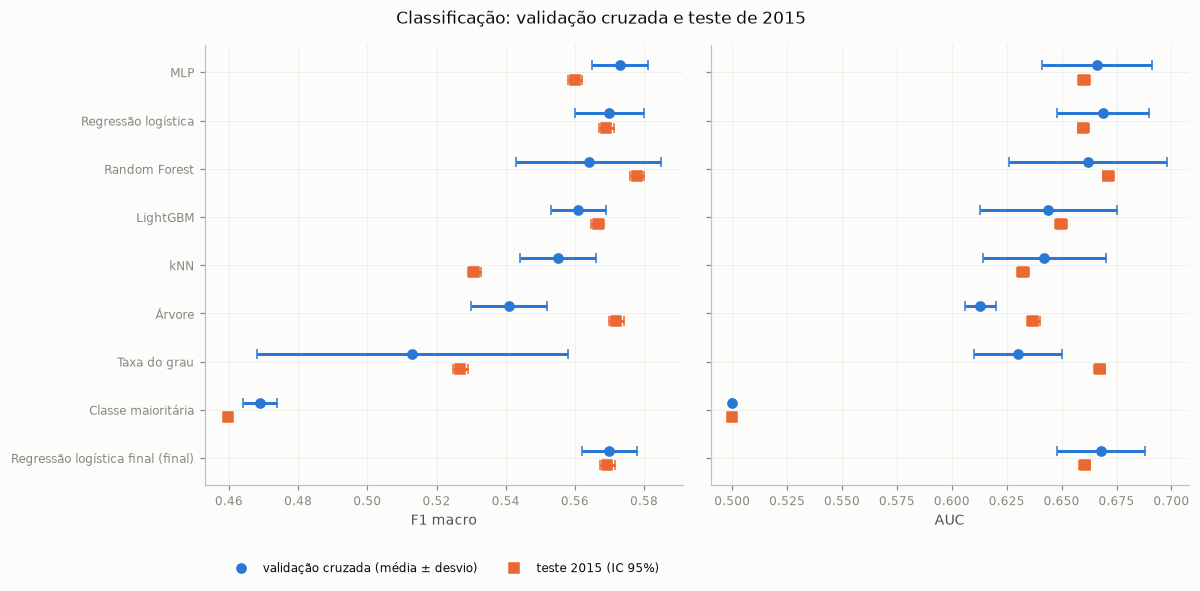

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 0.45 * len(cls.models) + 1.4), sharey=True)
cls.plot_cv_vs_test("f1_macro", ax=axes[0])
cls.plot_cv_vs_test("auc", ax=axes[1])
axes[1].get_legend().remove()
fig.suptitle("Classificação: validação cruzada e teste de 2015")
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "final_cls_cv_teste.png")
plt.show()

### 4.4 Matrizes de confusão do modelo final

A matriz 2 × 2 é a da classificação binária. A 3 × 2 separa as linhas pelas 3 classes do enunciado: mostra se os *At risk* (que no treino não existiam) caem do lado do *Default*, como a decisão binária pressupõe. As percentagens são de cada linha (a linha *Default* dá o *recall* de *Default*).

In [16]:
confusions = {"2 x 2": cls.confusion(), "2 x 2 (%)": cls.confusion(percent=True),
              "3 x 2": cls.confusion(three_classes=True), "3 x 2 (%)": cls.confusion(three_classes=True, percent=True)}
pd.concat(confusions).to_csv(RESULTS_DIR / "classification_test_confusion.csv")
for name, table in confusions.items():
    print(f"\n{name} ({cls.final_model}, limiar {cls.threshold(cls.final_model)})")
    print(table.to_string())


2 x 2 (Regressão logística final, limiar 0.57)
previsto       Good standing  Default
real                                 
Good standing         194006    46786
Default                26629    15575

2 x 2 (%) (Regressão logística final, limiar 0.57)
previsto       Good standing  Default
real                                 
Good standing           80.6     19.4
Default                 63.1     36.9

3 x 2 (Regressão logística final, limiar 0.57)
previsto       Good standing  Default
real                                 
Good standing         194006    46786
At risk                   51       24
Default                26578    15551

3 x 2 (%) (Regressão logística final, limiar 0.57)
previsto       Good standing  Default
real                                 
Good standing           80.6     19.4
At risk                 68.0     32.0
Default                 63.1     36.9


### 4.5 Mudança temporal: o risco ao longo de 2015

A taxa real de *Default* por mês de emissão, a percentagem que o modelo final classifica como *Default* e a P(Default) média. Se a P(Default) média ficar sempre abaixo da taxa real, o modelo subestima o risco de 2015 (os anos de treino eram menos arriscados, como a EDA mostrou), mesmo que ordene bem os empréstimos (AUC).

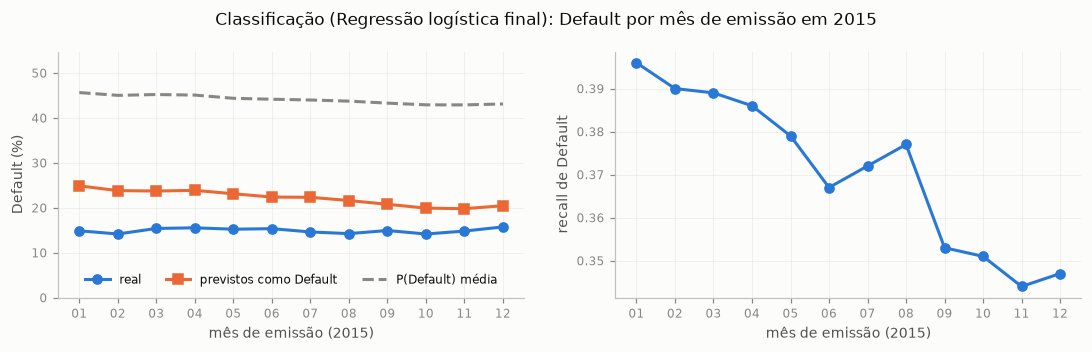

,n,Default real (%),Default previstos (%),P(Default) média (%),recall Default,falsos alarmes (%),AUC
2015-01,23622.0,14.884,24.884,45.640,0.396,22.302,0.656
2015-02,16021.0,14.169,23.819,45.021,0.390,21.308,0.661
2015-03,16910.0,15.405,23.732,45.202,0.389,20.965,0.660
2015-04,23610.0,15.544,23.880,45.080,0.386,21.179,0.651
2015-05,21532.0,15.233,23.124,44.364,0.379,20.474,0.659
2015-06,19058.0,15.358,22.390,44.156,0.367,19.794,0.654
2015-07,30856.0,14.623,22.336,43.989,0.372,19.788,0.661
2015-08,23921.0,14.255,21.617,43.735,0.377,18.946,0.666
2015-09,18764.0,14.944,20.779,43.292,0.353,18.221,0.668
2015-10,33181.0,14.168,19.930,42.912,0.351,17.419,0.663


In [17]:
cls_months = cls.by_period()
axes = cls.plot_by_period()
axes[0].figure.suptitle(f"Classificação ({cls.final_model}): Default por mês de emissão em 2015")
axes[0].figure.tight_layout()
axes[0].figure.savefig(config.FIGURES_DIR / "final_cls_por_mes.png")
plt.show()
cls_months

### 4.6 Equidade: recall e falsos alarmes por grupo

Para cada grupo: a taxa real de *Default*, o *recall* de *Default* (defaults que o modelo apanha) e os falsos alarmes (bons empréstimos classificados como *Default*, que na prática seriam recusados ou mais caros). Diferenças grandes de falsos alarmes entre grupos com a mesma taxa real seriam um problema de equidade; diferenças que acompanham a taxa real são o modelo a fazer o seu trabalho, e convém separar as duas coisas na discussão.

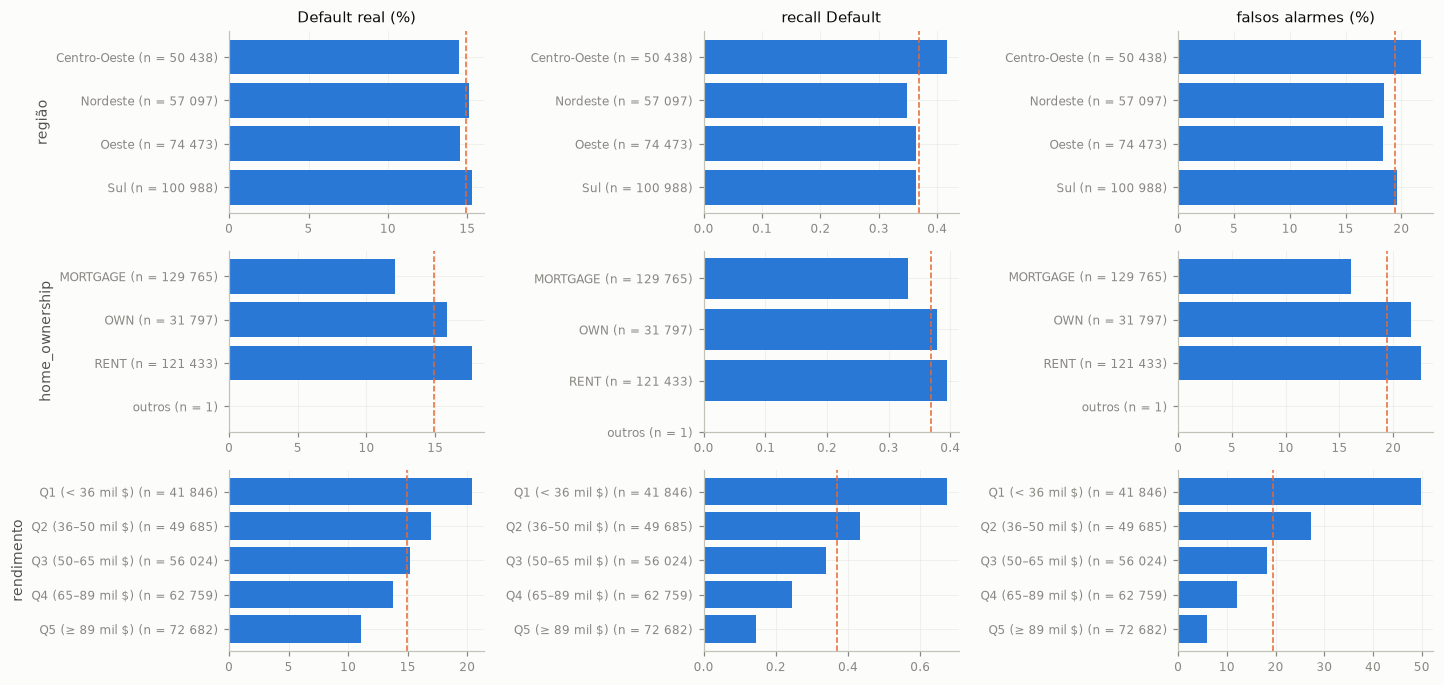

n  Default real (%)  \
região         Centro-Oeste       50438.0            14.489   
               Nordeste           57097.0            15.095   
               Oeste              74473.0            14.538   
               Sul               100988.0            15.299   
               total             282996.0            14.913   
home_ownership MORTGAGE          129765.0            12.091   
               OWN                31797.0            15.851   
               RENT              121433.0            17.684   
               outros                 1.0             0.000   
               total             282996.0            14.913   
rendimento     Q1 (< 36 mil $)    41846.0            20.403   
               Q2 (36–50 mil $)   49685.0            16.917   
               Q3 (50–65 mil $)   56024.0            15.231   
               Q4 (65–89 mil $)   62759.0            13.781   
               Q5 (≥ 89 mil $)    72682.0            11.116   
               total             282996.0            14.913   

                                 Default previstos (%)  P(Default) média (%)  \
região         Centro-Oeste                     24.642                45.207   
               Nordeste                         20.907                43.316   
               Oeste                            20.975                43.577   
               Sul                              22.155                44.103   
               total                            22.036                44.002   
home_ownership MORTGAGE                         18.187                41.660   
               OWN                              24.263                44.714   
               RENT                             25.566                46.318   
               outros                            0.000                56.534   
               total                            22.036                44.002   
rendimento     Q1 (< 36 mil $)                  53.434                58.076   
               Q2 (36–50 mil $)                 29.979                49.466   
               Q3 (50–65 mil $)                 20.609                45.140   
               Q4 (65–89 mil $)                 13.698                40.883   
               Q5 (≥ 89 mil $)                   6.828                33.981   
               total                            22.036                44.002   

                                 recall Default  falsos alarmes (%)    AUC  
região         Centro-Oeste               0.416              21.771  0.671  
               Nordeste                   0.348              18.431  0.658  
               Oeste                      0.363              18.369  0.663  
               Sul                        0.363              19.605  0.656  
               total                      0.369              19.430  0.660  
home_ownership MORTGAGE                   0.332              16.120  0.668  
               OWN                        0.379              21.695  0.646  
               RENT                       0.394              22.601  0.646  
               outros                       NaN               0.000    NaN  
               total                      0.369              19.430  0.660  
rendimento     Q1 (< 36 mil $)            0.673              49.868  0.621  
               Q2 (36–50 mil $)           0.434              27.253  0.634  
               Q3 (50–65 mil $)           0.339              18.225  0.649  
               Q4 (65–89 mil $)           0.244              11.990  0.657  
               Q5 (≥ 89 mil $)            0.146               5.856  0.670  
               total                      0.369              19.430  0.660

In [18]:
cls_groups = pd.concat({by: cls.subgroup_table(by) for by in GROUPS})
cls_groups.to_csv(RESULTS_DIR / "classification_test_subgroups.csv")
fig = cls.plot_subgroups(GROUPS, ["Default real (%)", "recall Default", "falsos alarmes (%)"])
fig.savefig(config.FIGURES_DIR / "final_cls_equidade.png")
plt.show()
cls_groups

## 5. Mudança temporal: as variáveis no treino e no teste

Só agora, com os modelos congelados, se comparam as distribuições do treino e do teste. O PSI (*population stability index*) resume a mudança de cada variável: abaixo de 0,1 é estável, de 0,1 a 0,25 é uma mudança moderada e acima de 0,25 é uma mudança grande. Na classificação a distância é grande por construção (treino de 2007–2011, teste de 2015); na regressão o treino acaba em 2014.

In [19]:
drift = pd.concat({
    "regressão": reg.drift_table(["int_rate", "fico_range_low", "dti", "annual_inc", "loan_amnt",
                                  "revol_util", "emp_length", "term", "home_ownership", "purpose"]),
    "classificação": cls.drift_table([config.CLASS_COL, "int_rate", "grade", "fico_range_low", "dti",
                                      "annual_inc", "loan_amnt", "revol_util", "home_ownership", "purpose"]),
})
drift.to_csv(RESULTS_DIR / "test_drift.csv")
drift

treino  \
              coluna                                     
regressão     int_rate                           14.05   
              dti                                17.74   
              revol_util                         56.74   
              emp_length                          6.15   
              purpose         debt_consolidation (60%)   
              loan_amnt                       14809.38   
              home_ownership            MORTGAGE (52%)   
              fico_range_low                    693.41   
              annual_inc                      74264.01   
              term                               42.96   
classificação purpose         debt_consolidation (45%)   
              dti                                13.07   
              fico_range_low                    713.06   
              loan_amnt                        9533.78   
              revol_util                         48.03   
              int_rate                           11.23   
              grade                            A (31%)   
              home_ownership                RENT (50%)   
              annual_inc                      67495.95   
              target                     12.3% Default   

                                                 teste  em falta treino (%)  \
              coluna                                                          
regressão     int_rate                           12.60                  0.0   
              dti                                19.15                  0.0   
              revol_util                         53.84                  0.1   
              emp_length                          6.03                  4.9   
              purpose         debt_consolidation (59%)                  0.0   
              loan_amnt                       15239.23                  0.0   
              home_ownership            MORTGAGE (49%)                  0.0   
              fico_range_low                    693.65                  0.0   
              annual_inc                      76968.39                  0.0   
              term                               43.86                  0.0   
classificação purpose         debt_consolidation (57%)                  0.0   
              dti                                18.48                  0.0   
              fico_range_low                    693.64                  0.0   
              loan_amnt                       12806.10                  0.0   
              revol_util                         52.28                  0.3   
              int_rate                           11.28                  0.0   
              grade                            B (32%)                  0.0   
              home_ownership            MORTGAGE (46%)                  0.0   
              annual_inc                      74526.24                  0.0   
              target                     14.9% Default                  0.0   

                              em falta teste (%)    PSI  
              coluna                                     
regressão     int_rate                       0.0  0.126  
              dti                            0.0  0.035  
              revol_util                     0.0  0.019  
              emp_length                     5.7  0.011  
              purpose                        0.0  0.006  
              loan_amnt                      0.0  0.005  
              home_ownership                 0.0  0.004  
              fico_range_low                 0.0  0.003  
              annual_inc                     0.0  0.003  
              term                           0.0  0.000  
classificação purpose                        0.0  0.485  
              dti                            0.0  0.429  
              fico_range_low                 0.0  0.371  
              loan_amnt                      0.0  0.199  
              revol_util                     0.0  0.154  
              int_rate                       0

## 6. Resumo para o relatório e para o sumário executivo

Os números principais, calculados a partir das tabelas acima.

In [20]:
# Regressão
r, test_r = reg.final_model, reg.test_metrics()
mean, std = parse_mean_std(reg.entries[r]["cv"].get("mae"))
mae = test_r.loc[r, "mae"]
print(f"REGRESSÃO - {r}: MAE no teste {mae:.3f} p.p. {reg_table.loc[r, 'IC 95% MAE']} "
      f"(CV {mean:.3f} ± {std:.3f}: {'dentro' if abs(mae - mean) <= std else 'fora'} de um desvio)")
for base in ["Mediana por prazo", "Mediana"]:
    if base in test_r.index:
        print(f"  melhoria face à {base.lower()}: {100 * (1 - mae / test_r.loc[base, 'mae']):.1f}%")
print(f"  R² no teste {test_r.loc[r, 'r2']:.3f}; viés médio {reg_months['viés'].mean():+.3f} p.p. "
      f"(meses de {reg_months['viés'].min():+.3f} a {reg_months['viés'].max():+.3f})")

# Classificação
c, test_c = cls.final_model, cls.test_metrics()
conf = cls.confusion()
caught = conf.loc["Default", "Default"] / conf.loc["Default"].sum()
alarms = conf.loc["Good standing", "Default"] / conf.loc["Good standing"].sum()
three = cls.confusion(three_classes=True)
print(f"\nCLASSIFICAÇÃO - {c} (limiar {cls.threshold(c)}): F1 macro {test_c.loc[c, 'f1_macro']:.3f} "
      f"{cls_table.loc[c, 'IC 95% F1 macro']}, AUC {test_c.loc[c, 'auc']:.3f} {cls_table.loc[c, 'IC 95% AUC']}")
print(f"  em cada 100 defaults de 2015, o modelo apanha {100 * caught:.0f}; "
      f"em cada 100 bons empréstimos, marca {100 * alarms:.0f} como Default")
if three.loc["At risk"].sum():
    print(f"  At risk classificados como Default: {100 * three.loc['At risk', 'Default'] / three.loc['At risk'].sum():.0f}% "
          f"({three.loc['At risk'].sum():,} empréstimos)")
print(f"  Default real no teste {100 * (cls.y == 'Default').mean():.1f}% "
      f"(no treino {100 * (cls.train[config.CLASS_COL] == 'Default').mean():.1f}%); "
      f"P(Default) média prevista {100 * cls.predict()[c].mean():.1f}%")

# Equidade e deriva
for name, groups, column in [("regressão", reg_groups, "viés"), ("classificação", cls_groups, "falsos alarmes (%)")]:
    for by in GROUPS:
        part = groups.loc[by].drop(index=["total", "outros"], errors="ignore")   # "outros": grupos pequenos
        print(f"\n{name}, {by}: {column} de {part[column].min():.2f} ({part[column].idxmin()}) "
              f"a {part[column].max():.2f} ({part[column].idxmax()})", end="")
print()
for name in ["regressão", "classificação"]:
    top = drift.loc[name].head(3)
    print(f"\nMaior mudança ({name}): " + ", ".join(f"{col} (PSI {psi:.2f})" for col, psi in top["PSI"].items()))

REGRESSÃO - LightGBM: MAE no teste 2.690 p.p. [2.685; 2.696] (CV 2.144 ± 0.419: fora de um desvio)
  melhoria face à mediana por prazo: 21.5%
  melhoria face à mediana: 27.8%
  R² no teste 0.416; viés médio +1.733 p.p. (meses de +1.452 a +2.093)

CLASSIFICAÇÃO - Regressão logística final (limiar 0.57): F1 macro 0.569 [0.567; 0.572], AUC 0.660 [0.658; 0.663]
  em cada 100 defaults de 2015, o modelo apanha 37; em cada 100 bons empréstimos, marca 19 como Default
  At risk classificados como Default: 32% (75 empréstimos)
  Default real no teste 14.9% (no treino 12.3%); P(Default) média prevista 44.0%

regressão, região: viés de 1.67 (Sul) a 1.81 (Centro-Oeste)
regressão, home_ownership: viés de 1.70 (MORTGAGE) a 1.81 (RENT)
regressão, rendimento: viés de 1.45 (Q1 (< 42 mil $)) a 2.07 (Q5 (≥ 97 mil $))
classificação, região: falsos alarmes (%) de 18.37 (Oeste) a 21.77 (Centro-Oeste)
classificação, home_ownership: falsos alarmes (%) de 16.12 (MORTGAGE) a 22.60 (RENT)
classificação, rendiment

**O que discutir no relatório** (secção de avaliação, com os quatro temas que o enunciado obriga):

1. **Generalização.** O valor no teste contra a média ± desvio da validação cruzada (3.2 e 4.2). Se o modelo final continua à frente das *baselines* e se a diferença para o 2.º se mantém (3.3 e 4.3).
2. **Mudança temporal.** O erro e o viés ao longo de 2015 (3.4 e 4.5) e as variáveis que mais mudaram (secção 5). Na classificação, a distância entre o treino (2007–2011) e o teste (2015) é a maior limitação do desenho; ligar às recomendações de retreino do plano de deployment.
3. **Follow-up desigual.** Resolvido pelo desenho: só 36 meses e só com o prazo terminado. Os números da secção 2 (60 meses e `Current` removidos) e a tabela 3 × 2 (4.4) mostram o custo e onde caem os *At risk*.
4. **Viés de seleção.** Os modelos só viram pedidos aceites; os rejeitados têm um *risk score* muito mais baixo (testes de hipóteses da Parte 1). Os resultados do teste valem para a população que a LendingClub aprovou em 2015, não para todos os pedidos.
5. **Equidade.** As diferenças entre grupos (3.5 e 4.6), separando o que acompanha a taxa real de *Default* do que não acompanha. A geografia ficou fora dos modelos.
6. **Se algum resultado for mau:** reportar e explicar; os modelos não mudam depois de ver o teste.